In [2]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt
import importlib

### other
import mrcfile

### my modules
from fast_volume_align_ot import utils, plots, transforms, signals, fle_3d, alignments, distances

### testing
from scipy import integrate
from scipy.stats import norm
from scipy.special import erf, erfinv

In [3]:
### These come from chatGPT
### for evaluating the ICDF from a 3D Gaussian after projecting to 1D

# def compute_icdf(N, sigma):
#     # Total mass (upper bound of y)
#     ymax = 2 * np.pi * sigma * np.sqrt(2 * np.pi)
#     # ymax = 1
    
#     # Grid in y (avoid exact 0 and ymax to prevent ±inf)
#     eps = 1e-12
#     y = np.linspace(eps, ymax - eps, N)
    
#     # Normalize to [0,1]
#     u = y / ymax
    
#     # ICDF (quantile function)
#     s = norm.ppf(u)
    
#     return y, s

    
# def compute_icdf_erf(N, sigma):
#     ymax = 2 * np.pi * sigma * np.sqrt(2 * np.pi)
    
#     eps = 1e-12
#     y = np.linspace(eps, ymax - eps, N)
    
#     u = y / ymax
#     s = np.sqrt(2) * erfinv(2 * u - 1)
    
#     return y, s

In [4]:
N = 65
d = 3
sigma = 5

f = utils.gaussian_3d(N, sigma=sigma)
g = utils.gaussian_3d(N, sigma=sigma)

# f = np.ones((N,N,N))
# g = np.ones((N,N,N))

f = signals.Signal(f, d=3, dx=1).preprocess_signals()[0] 
g = signals.Signal(g, d=3, dx=1).preprocess_signals()[0]

### grid for odd vs even?
# z = np.linspace(-1, 1, N, endpoint=True)
z = np.linspace(-(1 - (1/N)), 1 - (1/N), N, endpoint=True) 

print(f.shape)
print(np.sum(f))

(65, 65, 65)
1.0000000000000002


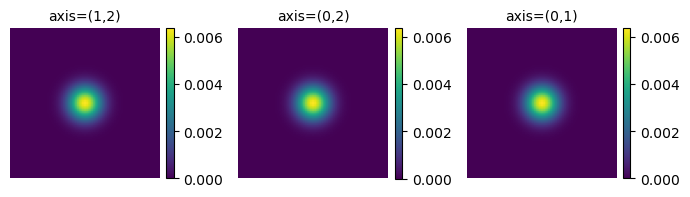

In [5]:
plots.orthogonal_2D_projection_plot(f)

In [6]:
### EV: Note setting normalize=True
###     this shouldn't matter for a centered Gaussian
###     but the RT is not giving \int = 1 as of now

f_rt = transforms.Transform(f, d=3).radon_transform()[0]
f_cdf = transforms.Transform(f, d=3).cdf_transform(normalize=True)[0]
f_icdf = transforms.Transform(f, d=3).inverse_cdf_transform(normalize=True)[0]

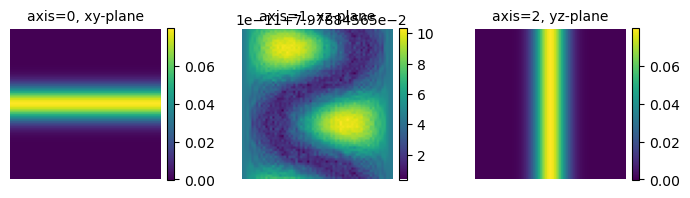

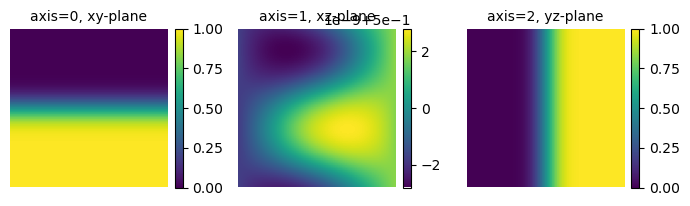

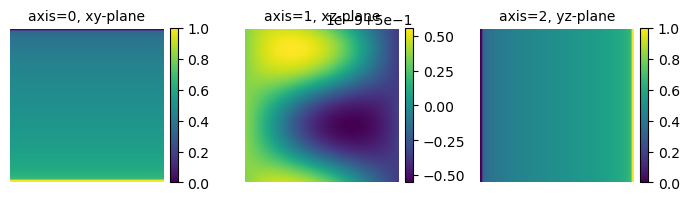

In [7]:
plots.orthogonal_2D_slice_plot(f_rt)
plots.orthogonal_2D_slice_plot(f_cdf)
plots.orthogonal_2D_slice_plot(f_icdf)

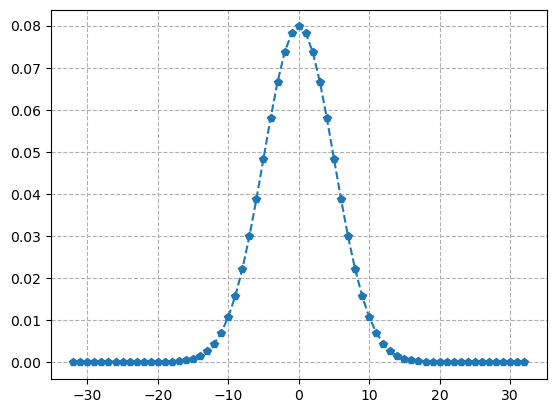

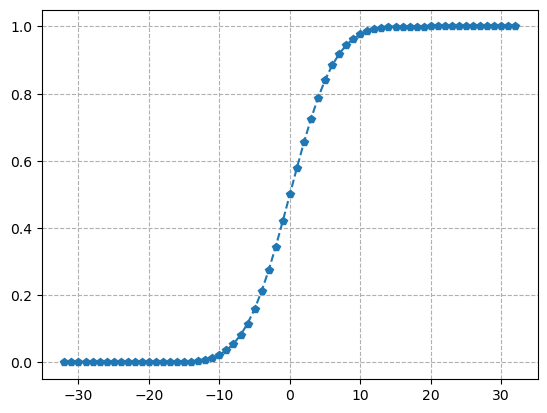

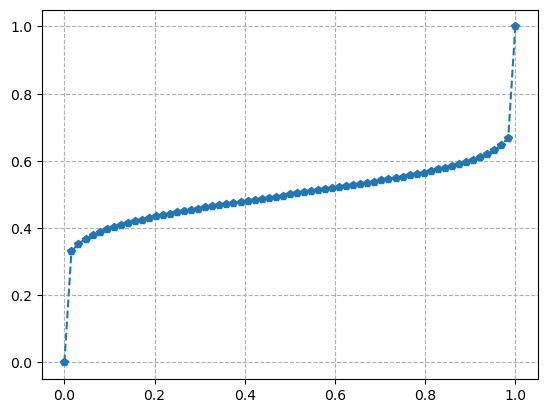

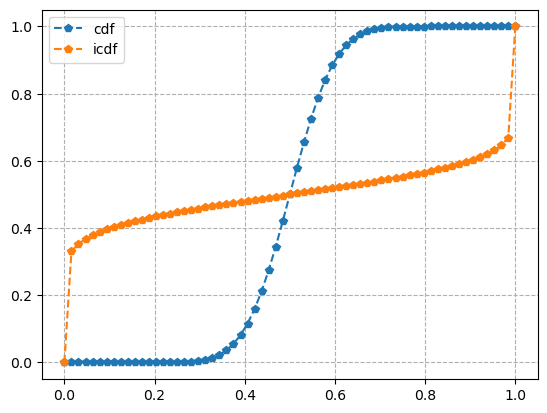

In [12]:
# plt.plot(f_rt[0, :, 0], 'p--')
# plt.show()
# plt.plot(f_cdf[0, :, 0], 'p--')
# plt.show()
# plt.plot(f_icdf[0, :, 0], 'p--')
# plt.show()

### EV: trying to show correct grid
t = np.linspace(0, 1, N, endpoint=True)

plt.plot(z, f_rt[0, :, 0], 'p--')
plt.grid(which='major', linestyle='--')
plt.show()
plt.plot(z, f_cdf[0, :, 0], 'p--')
plt.grid(which='major', linestyle='--')
plt.show()
plt.plot(t, f_icdf[0, :, 0], 'p--')
plt.grid(which='major', linestyle='--')
plt.show()

plt.plot(t, f_cdf[0, :, 0], 'p--', label='cdf')
plt.plot(t, f_icdf[0, :, 0], 'p--', label='icdf')
plt.legend()
plt.grid(which='major', linestyle='--')
plt.show()

In [9]:
np.sum(f_rt[0, :, 0]) 

0.9999999999995657

In [10]:
### Because strange grid used for defining the Gaussian and sigma 
z = np.arange(N) - (N - 1) / 2

f_erf = 0.5 * ( 1 + erf( z / (np.sqrt(2)*sigma) ) )

f_scipy = norm.cdf(z, 0, sigma)

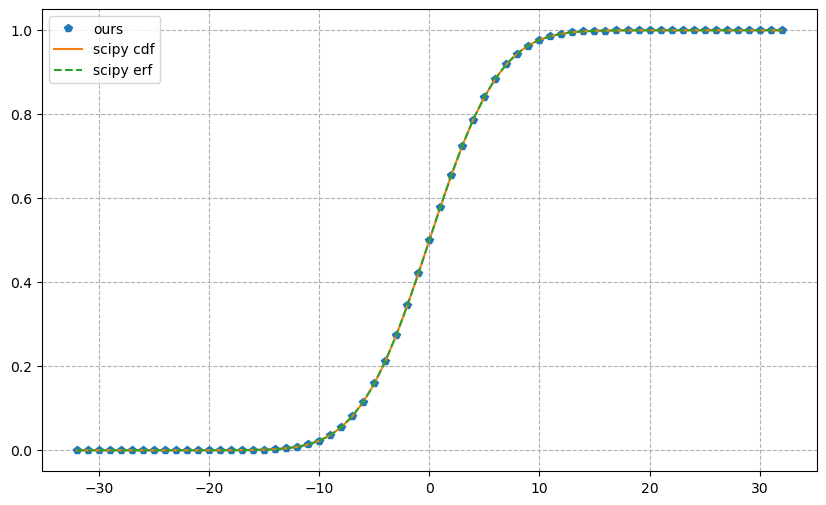

In [11]:
plt.figure(figsize=(10,6))
plt.plot(z, f_cdf[0, :, 0], 'p', label='ours')
plt.plot(z, f_scipy, '-', label='scipy cdf')
plt.plot(z, f_erf, '--', label='scipy erf')
plt.legend()
plt.grid(which='major', linestyle='--')
plt.show()

In [15]:
print(np.allclose(f_cdf[0,:,0], f_erf))
print(np.allclose(f_cdf[0,:,0], f_scipy))
print(np.allclose(f_erf, f_scipy))

False
False
True


In [ ]:
####

### try different quadrature

### 1) define the grid according to the overleaf
### 2) compute the ICDF using Clenshaw-Curtis
### 3) compare to analytical value

####

In [23]:
### z-grid is defined from [-1, 1], in unit ball

### but we change the notation after doing the Radon transform?
### so that it becomes [0, 1] instead?

### want to compute the ICDF and comparte it to the analytical function

### DOES NOT INCLUDE THE STANDARD NORMALIZATION

N = 65
sigma = 0.2

### grid for odd vs even?
# z = np.linspace(-1, 1, N, endpoint=True)
z = np.linspace(-(1 - (1/N)), 1 - (1/N), N, endpoint=True) 
dz = z[1]-z[0]

f = np.exp(- 0.5 * z**2 / (sigma**2))
f = f / (np.sum(f) * dz)

f_cdf = transforms.cumulative_trapezoid(f, z)

print(np.sum(f))
print(np.sum(f) * dz)
print(f_cdf[-1])

32.5
1.0
1.0


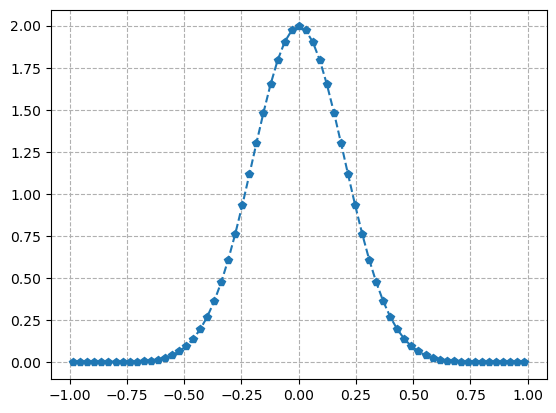

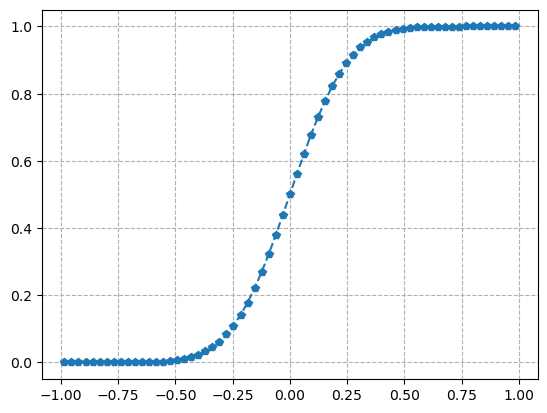

In [24]:
plt.plot(z, f, 'p--')
plt.grid(which='major', linestyle='--')
plt.show()

plt.plot(z, f_cdf, 'p--')
plt.grid(which='major', linestyle='--')
plt.show()

In [25]:
f_scipy = norm.cdf(z, 0, sigma)

f_erf = 0.5 * ( 1 + erf( z / (np.sqrt(2)*sigma) ) )

# f_c = np.cumsum(f)
# f_c = f_c / f_c[-1]

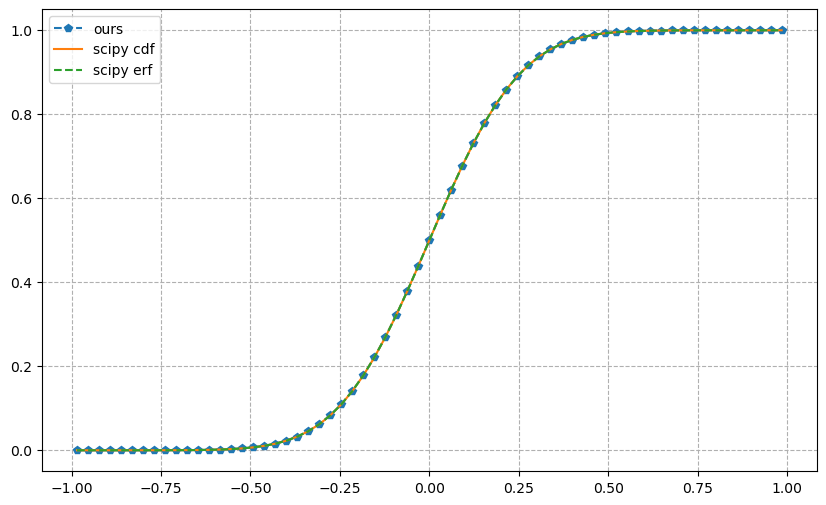

In [32]:
plt.figure(figsize=(10,6))
plt.plot(z, f_cdf, 'p--', label='ours')
plt.plot(z, f_scipy, '-', label='scipy cdf')
plt.plot(z, f_erf, '--', label='scipy erf')
plt.legend()
plt.grid(which='major', linestyle='--')
plt.show()

In [27]:
print(np.allclose(f_cdf, f_erf))
print(np.allclose(f_erf, f_scipy))

False
True


In [ ]:
def compute_inverse_cdfs(P, x, u_grid):
    """
    Vectorized computation of inverse CDFs for a matrix P.
    Each column of P is a PDF defined on grid x.
   
    Parameters:
      P      : 2D numpy array of shape (len(x), M), with each column a PDF.
      x      : 1D numpy array of grid points.
      u_grid : 1D numpy array of values in [0,1] for evaluating the inverse CDF.
     
    Returns:
      inv_cdfs: 2D array of shape (len(u_grid), M) where each column is the inverse CDF.
    """
    
    dx = x[1] - x[0]
    # Normalize each column (if not already normalized)
    P_norm = P / (np.sum(P, axis=0) * dx)
    # Compute the CDFs along axis=0 (each column)
    CDF = np.cumsum(P_norm, axis=0) * dx
    # Normalize each column's CDF so that the last entry is 1
    CDF = CDF / CDF[-1, :]
   
    ny, nx = CDF.shape
    cp = u_grid.size
    
    ICDF = np.zeros((cp, nx))
    
    for idx in range(nx):
        # We set bounds_error=False and force fill_value=(x[0], x[-1]) so that u=0,1 map to x[0], x[-1].
        interpolator = interp1d(CDF[:, idx], x, axis=0, bounds_error=False, fill_value=(x[0], x[-1]), assume_sorted=True)
        ICDF[:, idx] = interpolator(u_grid)   
    
    return ICDF



def clenshaw_curtis(n):
    """
    Compute Clenshaw-Curtis nodes and weights for integration on [0,1].
   
    This function first computes Chebyshev nodes on [-1,1] using
       x_i = cos(pi * i/(n-1)), i=0,..., n-1,
    then transforms them to [0,1] via
       u = (1 - x)/2.
    The weights are computed using a standard algorithm.
   
    Parameters:
      n : int, number of nodes (n >= 2)
     
    Returns:
      u : 1D numpy array of nodes in [0,1] (nonuniform, clustering near 0 and 1)
      w : 1D numpy array of quadrature weights (summing to 1)
    """
    
    if n < 2:
        raise ValueError("n must be at least 2")
    k = np.arange(n)
    theta = np.pi * k / (n - 1)
    x_cc = np.cos(theta)       # nodes on [-1,1]
    u = (1 - x_cc) / 2         # transform to [0,1]
   
    w = np.zeros(n)
    if (n - 1) % 2 == 0:
        m = (n - 1) // 2
        for i in range(n):
            s = 0.0
            for j in range(1, m):
                s += 2 * np.cos(2 * j * theta[i]) / (4 * j**2 - 1)
            s += np.cos(2 * m * theta[i]) / (4 * m**2 - 1)
            w[i] = 2 / (n - 1) * (1 - s)
    else:
        m = (n - 1) // 2
        for i in range(n):
            s = 0.0
            for j in range(1, m + 1):
                s += 2 * np.cos(2 * j * theta[i]) / (4 * j**2 - 1)
            w[i] = 2 / (n - 1) * (1 - s)
    # These weights integrate on [-1,1] to 2, so divide by 2 to get integration over [0,1].
    w = w / 2
    
    return u, w



def average_squared_L2_distance_vectorized(P1, P2, x, num_cc=1000):
    """
    Compute the average squared L2 distance between inverse CDFs (quantile functions)
    for corresponding columns of P1 and P2 in a fully vectorized manner.
   
    For each column (each a PDF on grid x), we:
      1. Normalize the PDF.
      2. Compute its inverse CDF on a nonuniform grid u in [0,1] using Clenshaw-Curtis nodes,
         which cluster near 0 and 1 (capturing steep behavior in the tails).
      3. Compute the squared difference between the inverse CDFs for P1 and P2,
         and integrate using the Clenshaw-Curtis quadrature weights.
      4. Average the squared L2 distances over all columns.
   
    Parameters:
      P1, P2 : numpy arrays of shape (len(x), M), where each column is a PDF.
      x      : 1D numpy array of grid points (assumed uniformly spaced).
      num_cc : number of Clenshaw-Curtis nodes (default 1000).
     
    Returns:
      avg_sq_dist : average squared L2 distance between the inverse CDFs.
      col_sq_dist : 1D numpy array (length M) of the squared L2 distances per column.
    """
    
    dx = x[1] - x[0]
    # Get Clenshaw-Curtis nodes and weights on [0,1]
    u_cc, w_cc = clenshaw_curtis(num_cc)  # u_cc: shape (num_cc,), w_cc: shape (num_cc,)
   
    # Compute vectorized inverse CDFs for P1 and P2 (each shape: (num_cc, M))
    inv_cdfs1 = compute_inverse_cdfs(P1, x, u_cc)
    inv_cdfs2 = compute_inverse_cdfs(P2, x, u_cc)
   
    # Compute squared difference (shape: (num_cc, M))
    diff_sq = (inv_cdfs1 - inv_cdfs2) ** 2
    # Integrate along the u-axis using Clenshaw-Curtis weights (broadcast weights to all columns)
    col_sq_dist = np.sum(diff_sq * w_cc[:, np.newaxis], axis=0)
   
    avg_sq_dist = np.sqrt(np.mean(col_sq_dist))
    
    return avg_sq_dist